# Introduction to Flow Matching

## 0. Import Packages

If you havent already, do `module load clint mlclass` in a seperate terminal. Then select the `ML Class` kernel for this notebook

<b>Please execute this first cell now!</b> This will import all the necessary packages that we need.

In [1]:
# Utilities
import xarray as xr
from utils import prepare_cartopy, plot_netcdf, calculate_CRPS, MAE_masked, radial_psd
from tqdm import tqdm
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import os
import getpass
import mlflow


# Pytorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# Pytorch lightning
import lightning.pytorch as pl
from lightning.pytorch.loggers import WandbLogger, CSVLogger, MLFlowLogger
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch import Trainer


# 1. Load data

This is exactly the same as before

In [2]:
# define data parameters
data_dir = '/work/bk1318/mlclass/data/radolan'

data_train_name = "train.nc"
data_val_name = "val.nc"
data_test_name = "test.nc"

mask_name = "mask.nc"
variable = "pr"

# Load train, val, and test data
data_train = torch.as_tensor(xr.open_dataset("{}/{}".format(data_dir, data_train_name))[variable].values)
data_val = torch.as_tensor(xr.open_dataset("{}/{}".format(data_dir, data_val_name))[variable].values)
data_test = torch.as_tensor(xr.open_dataset("{}/{}".format(data_dir, data_test_name))[variable].values)

# Reshape for dataset creation and create datasets
time_train, lon, lat = data_train.shape
time_val, _, _ = data_val.shape
time_test, _, _ = data_test.shape

dataset_train = torch.utils.data.TensorDataset(data_train.reshape(time_train, 1, lon, lat))
dataset_val = torch.utils.data.TensorDataset(data_val.reshape(time_val, 1, lon, lat))
dataset_test = torch.utils.data.TensorDataset(data_test.reshape(time_test, 1, lon, lat))

# Load and reshape mask
mask = torch.as_tensor(xr.open_dataset("{}/{}".format(data_dir, mask_name))[variable].values).reshape(1, lon, lat)

In [3]:
# data loader parameters
batch_size = 128
number_of_threads = 4

# create data loader
train_dataloader = DataLoader(dataset_train, batch_size=batch_size, num_workers=number_of_threads)
val_dataloader = DataLoader(dataset_val, batch_size=batch_size, num_workers=number_of_threads)
test_dataloader = DataLoader(dataset_test, batch_size=batch_size, num_workers=number_of_threads)

# 2. First Guess Model Definition

We need to redefine the UNET from last exercise

In [4]:
# define the down convolution
class DownConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.down_conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)
        # batch normalization to make training more stable
        self.batch_norm = nn.BatchNorm2d(out_channels)
        # activation function to introduce non-linearity
        self.activation = nn.LeakyReLU()

    def forward(self, x):
        # x has shape (b, c, w, h)
        x = self.down_conv(x)
        x = self.batch_norm(x)
        return self.activation(x)


# define the up convolution
class UpConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)
        # batch normalization to make training more stable
        self.batch_norm = nn.BatchNorm2d(out_channels)
        # activation function to introduce non-linearity
        self.activation = nn.LeakyReLU()

    def forward(self, x, skip, batch_norm=True, activation=True):
        # x has shape (b, c, w, h)
        x = self.up(x)
        x = torch.cat([x, skip], dim=1) # concatenate x and skip in the channel dimension
        x = self.conv(x)
        if batch_norm:
            x = self.batch_norm(x)
        if activation:
            x = self.activation(x)
        return x

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.down1 = DownConv(1, 16)
        self.down2 = DownConv(16, 32)
        self.down3 = DownConv(32, 64)

        self.up1 = UpConv(32+64, 32)
        self.up2 = UpConv(32+16, 16)
        self.up3 = UpConv(16+1, 1)

    def forward(self, x0):
        #down
        x1 = self.down1(x0)
        x2 = self.down2(x1)
        x3 = self.down3(x2)
        #up
        x4 = self.up1(x3, skip=x2, batch_norm=True, activation=True)
        x5 = self.up2(x4, skip=x1, batch_norm=True, activation=True)
        # last layer without(!) batch norm and activation
        x6 = self.up3(x5, skip=x0, batch_norm=False, activation=False)
        return x6

# 3. Method: Probabilistic Residual Correction

The UNet above gives a single, deterministic infilling. But many different precipitation fields are *plausible* given the same observations. To capture this uncertainty we follow the idea of **CorrDiff** (Mardani et al., 2025): keep the trained UNet as a cheap **mean prediction** (the "first guess" $\hat{y}$) and train a small **diffusion model** to sample the **residual** $r = y - \hat{y}$ between the ground truth and that first guess. The final field is

$$ y = \hat{y} + r$$

Because the diffusion model only has to learn the *correction* (not the whole field), it is feasible to train in a couple of minutes.

**Which diffusion? → Flow matching (rectified flow).** Instead of a noise schedule (DDPM) or the EDM preconditioning, we use the simplest formulation that works well: a straight-line path between noise and data. 

## Define Problem

$$
r = y - \hat{y}
$$

$$
\hat{y}: \text{UNet estimate} \qquad y: \text{True Precipitation} \qquad r: \text{Residual}
$$

We frame this as a probabilistic problem: $r$ is sampled from a PDF and conditioned on $\hat{y}$:

$$
r \sim p(r \mid \hat{y})
$$

## Flow Matching

Construct a straight path between noise and data. Assume Gaussian noise:

$$
\varepsilon \sim \mathcal{N}(0,1)
$$

At $t=0$ (noise level $0$) we have pure noise $x_0 = \varepsilon$; at $t=1$ we have the ground truth $x_1 = r$. Assuming constant velocity and a straight line, we get:

$$
x_t = (1-t)\,\varepsilon + t\, r, \qquad t \in [0,1]
$$

The velocity associated with our true flow is easy to calculate (and independent of time/noise level):

$$
\Rightarrow \quad v \;=\; \dot{x}_t \;=\; r - \varepsilon \qquad \qquad v: \text{True Velocity}
$$

Our model will estimate the velocity $v_{\theta} (x,t)$. We calculate the loss with the Mean Squared Error with respect to the true velocity $v$:

$$
\mathcal{L} = \mathrm{MSE}\big(v_\theta,\, v\big)
$$

### Sampling at test time

Once trained, the denoising happens as several Euler steps of the learned velocity field:

$$
x(n) = x(n-1) + v_\theta\big(x,\; \hat{y} ,\; t\big) \cdot \Delta t,
\qquad \Delta t = \frac{1}{\text{N}}
$$
 where $n$ is the current denoising step and $N$ is the total number of steps.

## Code

### UNET for first guess

`Unet` class: Same structure as yesterday. We will load the weights from the previously trained model.

### A lightweight denoiser

In `DiffusionUNet` we reuse the same `DownConv` and `UpConv` blocks, but build a much smaller UNet (only two resolution levels, fewer channels). It takes three input channels stacked together:

1. the current noisy residual $x_t$,
2. a conditioning field: the frozen UNet first guess $\hat{y}$
3. the time $t$ broadcast as a constant channel (so the network knows where it is on the path).

It outputs one channel: the predicted velocity $v_{\theta}$.

### Flow Loss

`LightningFlowMatch` is a lightning module the wraps the denoiser and the frozen first-guess UNet.

- **`training_step` / `validation_step`**: use `_flow_loss` to calculate the velocity
- **`sample`**: draw noise and Euler-integrate the learned velocity field to produce residual samples.

## Code to implement:

In `DiffusionUNet` implement the `forward` method. Use the `UpConv` and `DownConv` helper classes:
- 2 down convolutions
- 1 up convolution with skip channel and batchnorm
- 1 up convolution with skip chanel, but no batchnorm and no activation

In `LightningFlowMatch._flow_loss` we calculate the first guess with the previously trained U-Net and the residual. We sample a random time $t$. Then you need to fill in the following steps:

- sample random inital noise ε
- calculate noisy image $x_t$
- calculate $v$
- let denoising UNet predict $v_\theta$
- calculate and return loss L

**Tip:** use `torch.randn_like` to generate an array of random numbers with mean zero and standard deviation one. This array will have the same dimension as your input argument. Check out `https://docs.pytorch.org/docs/main/generated/torch.randn_like.html`. 


In `LightningFlowMatch.sample` we do the full denoising from random noise to final estimate that is used at test time:

- calcualte $x(n)$ with $x(n-1)$ and $v_{\theta}$

(Further down you also have to set run name: `run_name` = "MY_AWESOME_RUN")


# 4: Exercise: Implement Code

### Reminder:
`1-mask` gives you the pixels where prediction should happen

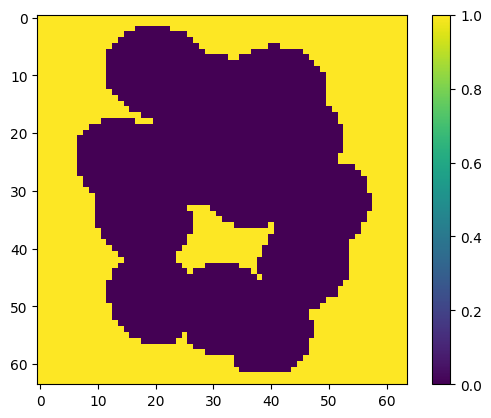

In [5]:
plt.imshow(1-mask[0])
plt.colorbar()

Torch random methods:

In [6]:
a = torch.zeros(2,3)
torch.randn_like(a)

tensor([[-1.2491,  0.4942,  1.9163],
        [-0.3544,  0.4276, -0.2926]])

In [7]:
# Lightweight residual denoiser: reuses DownConv / UpConv, two levels, few channels.
class DiffusionUNet(nn.Module):
    def __init__(self, in_channels=4, channels_1=16, channels_2=32):
        super().__init__()
        self.down1 = DownConv(in_channels, channels_1)       # 4 -> 16
        self.down2 = DownConv(channels_1, channels_2)        # 16 -> 32
        self.up1 = UpConv(channels_2 + channels_1, channels_1)          # 32 -> 16, skip x1
        self.up2 = UpConv(channels_1 + in_channels, 1)          # 16 -> 1, skip x0

    def forward(self, x_t, y_hat, masked_precip, t):
        # x_t, cond: (b, 1, H, W); t: (b, 1, 1, 1)
        t_channel = t.expand(x_t.shape[0], 1, x_t.shape[2], x_t.shape[3]) # construct time array with shape (batch, 1, H, W) to concatenate with x_t and cond
        x0 = torch.cat([x_t, y_hat, masked_precip, t_channel], dim=1)     # stack channels to construct x with shape (batch, in_channels, H, W). Use torch.cat: https://docs.pytorch.org/docs/2.14/generated/torch.cat.html
        x1 = self.down1(x0) # downconvolution
        x2 = self.down2(x1) # downconvolution
        y = self.up1(x2, skip=x1, batch_norm=True, activation=True) # upconvolution with batch norm and activation
        y = self.up2(y, skip=x0, batch_norm=False, activation=False) # upconvolution without batch norm and activation
        return y

In [8]:
class LightningFlowMatch(pl.LightningModule):
    def __init__(self, denoiser, first_guess_UNET, learning_rate, mask) :
        '''Lightning module for flow-matching with a diffusion model.

        Args:
            denoiser: The neural network used to predict the velocity.
            first_guess_UNET: The pre-trained UNet used for the first guess.
            learning_rate: Learning rate for the optimizer.
            mask: Mask to apply to the input data.
        '''
        super().__init__()
        
        self.denoiser = denoiser
        self.first_guess = first_guess_UNET.requires_grad_(False) # freeze layers of pretrained model
        self.learning_rate = learning_rate
        self.register_buffer('mask', mask) # moves mask to correct device automatically
        self.mask = mask

        
    def _flow_loss(self, batch):
        '''Compute the flow-matching loss for a given batch.

        Args:
            batch: A batch of ground truth data.

        Returns:
            The mean squared error loss between the predicted and target velocity.
        '''
        y = batch[0]
        self.first_guess.eval()                 # keep BatchNorm on running stats
        with torch.no_grad():
            y_hat = self.first_guess(y * self.mask)
        r = y - y_hat
        
        t = torch.rand(y.shape[0], 1, 1, 1).to(y.device) # sample random time t in [0, 1] for each sample in the batch
        noise = torch.randn_like(r)      # random noise with the same shape as residual
        x_t = (1 - t) * noise + t * r    # calculate x_t
        v_target = r - noise             # ground truth velocity 
        v_pred = self.denoiser(x_t, y_hat * (1-self.mask), y * self.mask, t) #let denoiser predict the velocity at time t given x_t and first_guess
        return F.mse_loss(v_pred  * (1 - self.mask), v_target * (1 - self.mask))  # calculate the mean squared error loss between predicted and target velocity, only on the unmasked regions. Use https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.mse_loss.html

    def training_step(self, batch, batch_idx):
        loss = self._flow_loss(batch)
        self.log("train_loss", loss, prog_bar=True, on_step=True, on_epoch=True, sync_dist=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self._flow_loss(batch)
        self.log("val_loss", loss)

    def configure_optimizers(self):
        return torch.optim.Adam(self.denoiser.parameters(), lr=self.learning_rate)

    @torch.no_grad()
    def predict_step(self, masked_precip, num_samples=1, steps=10):
        '''Sample from the flow-matching diffusion model.
        
        Args:
            masked_precip: The input data with missing values masked.
            num_samples: Number of samples to generate.
            steps: Number of integration steps.

        Returns:
            A tuple containing the first guess, the generated samples, and the noise path.
        '''
        self.denoiser.eval()
        self.first_guess.eval()
        y_hat = self.first_guess(masked_precip)
        samples = []
        sample_noise_path = torch.zeros((num_samples, steps, *tuple(masked_precip.shape[:])))
        for k in range(num_samples):
            x = torch.randn_like(y_hat)                       # t = 0: pure noise
            for i in range(steps):                                  # Euler integrate to t = 1
                t = torch.full((y_hat.shape[0], 1, 1, 1), i / steps)
                x = x + self.denoiser(x, y_hat * (1-self.mask), masked_precip, t) * (1.0 / steps)
                sample_noise_path[k,i] = x                          # store noisy intermediate images for later visualisation
            samples.append(y_hat + x)                         # y = mean + residual
        return y_hat, torch.stack(samples) , sample_noise_path

# 5 Complete model setup

Learning rate, max_epochs and setup callback.


In [9]:
# define training parameters
learning_rate = 0.0002
max_epochs = 45

# checkpoint callback: keep only the best checkpoint, ranked by validation loss
checkpoint_callback = ModelCheckpoint(dirpath="snapshots_diffusion/",
                                      auto_insert_metric_name=False,
                                      filename='best-epoch_{epoch}-val_loss_{val_loss:.4f}',
                                      monitor="val_loss",
                                      mode="min",
                                      save_top_k=1)

Set up Logging

In [10]:
# mlflow logger for online logging, csv logger for offline logging
experiment_name = "DL_Workshop_FlowMatching" # Dont change
run_name= "test"# Enter a unique name for your run
csv_logger = CSVLogger("logs", name=experiment_name)
logger_list = [csv_logger]

#mlflow.set_workspace("bk1444")
#mlflow_logger = MLFlowLogger(tracking_uri="https://mlflow.dkrz.de", experiment_name=experiment_name, run_name=run_name)
#logger_list.append(mlflow_logger)


Load model weights from yesterday for first guess

In [11]:
fg_ckpt = "pretrained_unet.ckpt"
first_guess_UNET = UNet()
_state = torch.load(fg_ckpt, map_location="cpu")["state_dict"]
first_guess_UNET.load_state_dict({k[len("model."):]: v for k, v in _state.items() if k.startswith("model.")})

<All keys matched successfully>

Set up denoiser and Flow machting lighnting module. 

- `in_channels`: Number of input channels for the denoiser: (x_t, first_guess * (1-mask), gt * mask, t)
- `diff_base_channels`: width of the denoiser (kept small for fast training).


In [ ]:
diff_base_channels = 32   # denoiser width 

denoiser = DiffusionUNet()
FlowMatchingModule = LightningFlowMatch(denoiser, first_guess_UNET, learning_rate, mask)

# 6: Training

Start Training:
(takes a couple of minutes)

In [ ]:
# Train the flow-matching residual model (only the small denoiser is optimized).
diff_trainer = Trainer(max_epochs=max_epochs,
                       callbacks=[checkpoint_callback],
                       logger=logger_list,
                       enable_progress_bar=True,
                        )

diff_trainer.fit(model=FlowMatchingModule, train_dataloaders=train_dataloader, val_dataloaders=val_dataloader)
print("Best checkpoint:", checkpoint_callback.best_model_path)
min_val_loss = checkpoint_callback.best_model_score.item()
print("Min val_loss:", min_val_loss)
#mlflow_logger.log_metrics({"min_val_loss": min_val_loss})


Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


/work/bk1444/mlclass/envs/tuto_pytorch/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /work/bk1444/mlclass/envs/tuto_pytorch/lib/python3.1 ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.s

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=45` reached.


Best checkpoint: /work/ka1176/paul/DL_course/introduction-to-machine-learning/probabilisitic_ml/ipynbs/snapshots_diffusion/best-epoch_44-val_loss_0.0392.ckpt
Min val_loss: 0.03916921466588974


### Loss curves

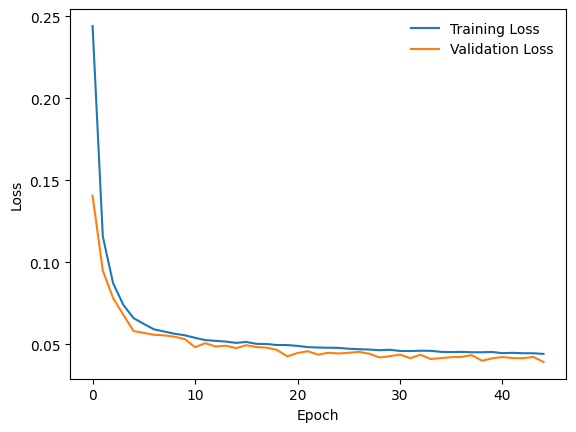

In [14]:
# read the logged data from the csv_logger
df = pd.read_csv(csv_logger.log_dir + "/metrics.csv")
train_df = df.dropna(subset=["train_loss_epoch"])
val_df = df.dropna(subset=["val_loss"])

# plot the loss curves
plt.plot(train_df["epoch"], train_df["train_loss_epoch"], label="Training Loss")
plt.plot(val_df["epoch"], val_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(frameon=False)
plt.show()

# 7: Evaluation:

Load the best (lowest val_loss) checkpoint into `FlowMatchingModule` before sampling. This overwrites the current model weights with the best checkpoint weights.

In [ ]:
best_ckpt = torch.load(checkpoint_callback.best_model_path, map_location="cpu")
FlowMatchingModule.load_state_dict(best_ckpt["state_dict"])

<All keys matched successfully>

Prepare Ground Truth from Test Dataset.

In [16]:
gts = data_test.unsqueeze(1) # ML convention for array shape: (n_samples, n_channels=1, H=64, W=64)
coords = xr.open_dataset("{}/{}".format(data_dir, data_test_name))[variable].coords
n_test = gts.shape[0] # number of test samples

## Make Ensemble Prediction

Just like the deterministic evaluation, we infill the test data — but now we draw **several plausible samples** per field. Each infilled field keeps the observed pixels and fills the missing region with `mean + sampled residual`. We use the `predict` method to generate plausible samples.\n,

- `num_realisations` : number of realisations (ensemble members) for each sample
- `sampling_steps` : Number of Euler-forward integration steps along the flow field

Our predict_step is more complicated compared to a standard deterministic model, therefore we use `FlowMatchingModule.predict_step()` and not `Trainer.predict()` (the latter only allows a dataloader as input argument)

In [ ]:
# draw several plausible samples for a batch of test fields
num_realisations = 10 
sampling_steps = 5
y_hat_test, samples, noisy_samples = FlowMatchingModule.predict_step(gts * mask, num_samples=num_realisations, steps=sampling_steps) 
y_hat_test = y_hat_test.cpu()     # (n_test, 1, H, W)
samples = samples.cpu()             # (num_realisations, n_test, 1, H, W)
noisy_samples = noisy_samples.cpu()             # (num_realisations, sampling_steps, n_test, 1, H, W)


## Plot Maps

In [18]:
# Helper mask for plotting
# bounding box of the missing (mask == 0) region -> defines the "central mask" crop
rows, cols = torch.where((1-mask[0]) == 0)
r0, r1 = 10, 55
c0, c1 = 20, 45
central_mask = torch.ones_like(mask)
central_mask[0,r0:r1, c0:c1] = mask[0,r0:r1, c0:c1]
mask_rep = mask.repeat(n_test, 1, 1, 1)
central_mask_rep = central_mask.repeat(n_test, 1, 1, 1)

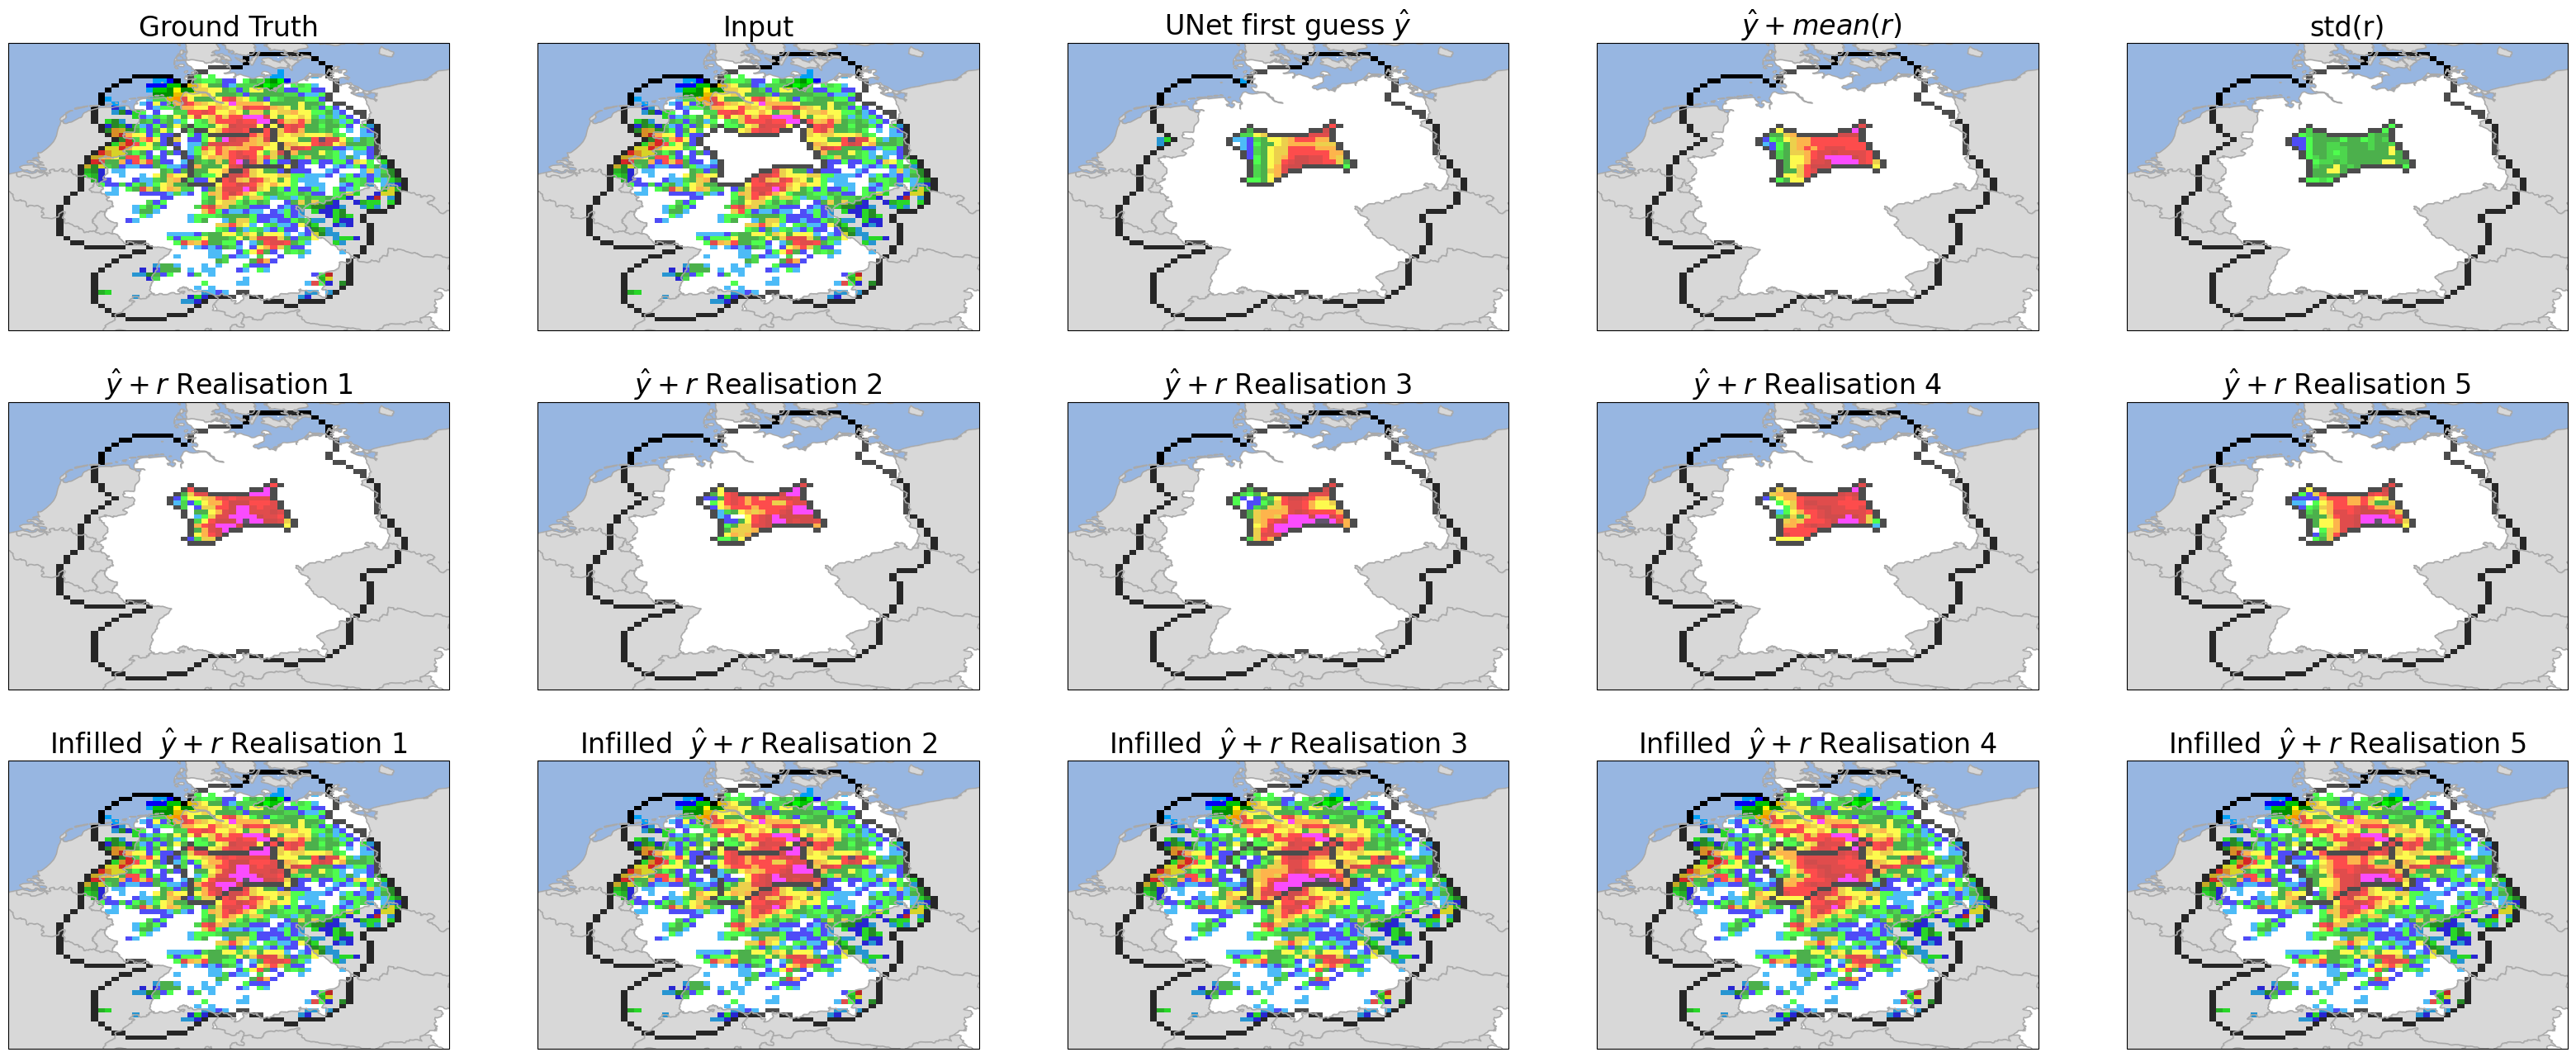

In [19]:
prepare_cartopy()

infilled_samples = mask * gts + (1 - central_mask) * samples

# draw one test sample ("one scene")
idx = 6

num_samples_plot = 5  # number of FM realisations to plot

fig, ax = plt.subplots(3, num_samples_plot, figsize=(5 * (num_samples_plot + 3), 16),
                       subplot_kw=dict(projection=ccrs.PlateCarree()))

plot_netcdf(gts, mask_rep, idx, ax[0, 0], "Ground Truth", coords)
plot_netcdf(gts * mask, mask_rep, idx, ax[0, 1], "Input", coords)
plot_netcdf(y_hat_test * (1 - mask), mask_rep, idx, ax[0, 2], "UNet first guess $\hat{y}$", coords)
plot_netcdf(infilled_samples.mean(dim=0) * (1 - mask) , mask_rep, idx, ax[0, 3], " $\hat{y} + mean(r)$", coords)
plot_netcdf(infilled_samples.std(dim=0) * (1 - mask) , mask_rep, idx, ax[0, 4], "std(r)", coords)

for k in range(num_samples_plot):
    plot_netcdf(infilled_samples[k] *(1 - mask) , mask_rep, idx, ax[1, k],  "$\hat{y} + r$" + f" Realisation {k + 1}", coords)
for k in range(num_samples_plot):
    plot_netcdf(infilled_samples[k] , mask_rep, idx, ax[2, k], "Infilled  $\hat{y} + r$" + f" Realisation {k + 1}", coords)

plt.show()

## Question to the Audience: What do you notice in the Flow Matching solution qualitatively?

The flow matching realisations show more extreme precipitation and, to some degree, more high frequency structures.

Calculate MAE as error metric

In [20]:
# Cacluate MSE for first guess and samples
mae_first_guess = MAE_masked(y_hat_test, gts, central_mask)
mae_samples = MAE_masked(samples.mean(axis=0), gts, central_mask)
print("MAE First Guess:", mae_first_guess)
print("MAE Flow Matching Samples:", mae_samples)


MAE First Guess: 0.5864269137382507
MAE Flow Matching Samples: 0.7063236832618713


## Question to audience: Why does the first guess UNET have a better MAE?

Because it was optimised on the MAE loss (also called L1 loss). The flow matching model was optimised on something more abstract (RMSE of the flow) and as a result has worse MAE. This highlights the importance of considering your optimisation target and your evaluation metrics.

## Probablisitic Evaluation: CRPS


The Continuous Ranked Probability Score (CRPS) measures how well a probabilistic forecast $y^{FM}_i$ matches a single observed value $y$. It generalises the mean absolute error to ensembles: for a deterministic forecast it reduces exactly to the absolute error, and it rewards ensembles that are both accurate (centred on the truth) and sharp (not over-dispersed). Lower is better.

For an ensemble of $M$ samples $\{y^{FM}_1, \dots, y^{FM}_M\}$ it can be estimated as

$$
\mathrm{CRPS} \;=\; \frac{1}{M}\sum_{i=1}^{M} |y^{FM}_i - y| \;-\; \frac{1}{2M^2}\sum_{i=1}^{M}\sum_{j=1}^{M} |y^{FM}_i - y^{FM}_j|.
$$

The first term penalises the distance of the members from the observation; the second term rewards ensemble spread. We evaluate it only over the masked-out (infilled) pixels, since those are the ones the model actually had to predict, and then average over all test fields and masked pixels.

You can think of CRPS as the area between two cumulative distrubution functions (where the ground truth and the deterministic forecast are just a step function)

![CRPS illustration](CRPS.webp)

In [21]:
# CRPS over the masked-out (infilled) region only.

crps_FM = calculate_CRPS(samples, gts, central_mask)
#mlflow_logger.log_metrics({"CRPS": crps_FM})

print(f"MAE First Guess: {mae_first_guess:.4f}")
print(f"MAE Flow Matching: {mae_samples:.4f}")
print(f"Mean CRPS: {crps_FM:.4f}")


MAE First Guess: 0.5864
MAE Flow Matching: 0.7063
Mean CRPS: 0.5559


# Bonus:
- visualise denoising process
- check out frequency spectra

## Plot denoising process

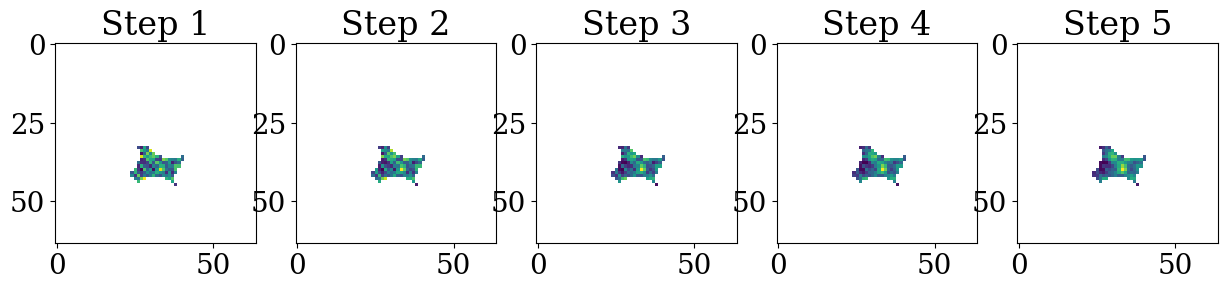

In [22]:
fig, axes = plt.subplots(1, 5, figsize = (15,5))

axes = axes.flatten()

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")  # render masked-out (outside central mask) region as white

for n in range(0, sampling_steps, 1) :
    ax = axes[n]
    # mask everything outside the central region so it shows as white background
    img = np.where(central_mask[0] == 0, noisy_samples[0, n, idx, 0], np.nan)
    ax.imshow(img, cmap=cmap)
    ax.set_title(f"Step {n +1}")

### Frequency spectra

A useful way to check whether the generated fields look *physically realistic* is to compare their **power spectra**. Precipitation fields have characteristic spatial structure across scales (large weather systems down to small convective cells), and a good model should reproduce the energy at each scale.

The cell below computes the **radially-averaged 2D power spectral density (PSD)**:

1. Take the 2D Fourier transform of each field and square its magnitude to get the power at every 2D wavenumber $(k_x, k_y)$.
2. Bin this power by radial wavenumber $k = \sqrt{k_x^2 + k_y^2}$ and average within each ring, collapsing the 2D spectrum to a 1D curve of power vs. spatial scale (low $k$ = large scales, high $k$ = small scales).

We compute the PSD over the cropped central (infilled) region for the ground truth, the deterministic UNet mean, and the flow-matching samples, then average over all test fields and plot them on log-log axes.


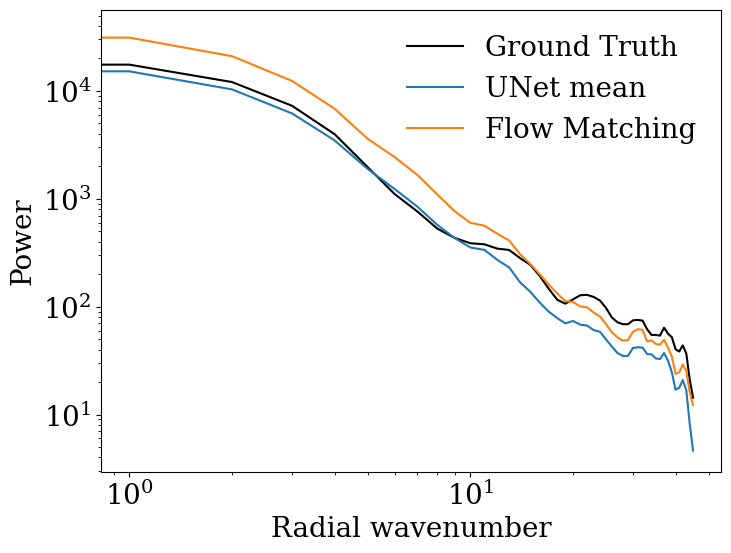

In [23]:
import numpy as np

# crop the central region out of ground truth, UNet mean and diffusion samples
gt_crop = gts.squeeze() * (1-central_mask[0])
fg_crop = y_hat_test.squeeze() * (1-central_mask[0])
samples_crop = samples.squeeze()* (1-central_mask[0])  # (num_samples, n_eval, h, w)

# radially-averaged PSD, averaged over all test samples (and diffusion samples)
psd_gt = radial_psd(gt_crop.numpy()).mean(axis=0)
psd_fg = radial_psd(fg_crop.numpy()).mean(axis=0)
psd_diff = radial_psd(samples_crop.numpy()).mean(axis=(0,1))

fig, ax = plt.subplots(figsize=(8, 6))

plt.loglog(psd_gt, label="Ground Truth", color="black")
plt.loglog(psd_fg, label="UNet mean")
#plt.loglog(psd_diff, label="Diffusion samples")
#for i in range(psd_diff.shape[0]) :
plt.loglog(psd_diff, color="tab:orange", label="Flow Matching")
plt.xlabel("Radial wavenumber")
plt.ylabel("Power")
plt.legend(frameon=False)
plt.show()